# <center>**TSA Complaint Hotspots**

### Project Overview

Analyzed TSA complaint records by airport, complaint category, and reporting period to identify trends and operational priorities. The analysis focuses on opportunities for targeted training, resource allocation, and operational improvements.

In [1]:
# Loading the packages needed for analysis and visual creations

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from pathlib import Path
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

In [2]:
# Loading datasets, reading them and looking at first few lines

files = {
    "by_airport": "complaints-by-airport.csv",
    "by_category": "complaints-by-category.csv",
    "by_subcategory": "complaints-by-subcategory.csv",
    "iata_icao": "iata-icao.csv"}

dfs = {}

for name, path in files.items():
    df = pd.read_csv(path)
    dfs[name] = df
    print(f"=== {name} ===")
    print(f"Shape: {df.shape}")
    print("Columns:", df.columns.tolist())
    display(df.head(5))

=== by_airport ===
Shape: (41721, 4)
Columns: ['pdf_report_date', 'airport', 'year_month', 'count']


,pdf_report_date,airport,year_month,count
0,2019-02,ABE,2015-01,0
1,2019-02,ABE,2015-02,0
2,2019-02,ABE,2015-03,0
3,2019-02,ABE,2015-04,0
4,2019-02,ABE,2015-05,2


=== by_category ===
Shape: (241588, 7)
Columns: ['pdf_report_date', 'airport', 'category', 'year_month', 'count', 'clean_cat', 'clean_cat_status']


,pdf_report_date,airport,category,year_month,count,clean_cat,clean_cat_status
0,2019-02,ABE,Hazardous Materials Safety,2015-01,0,Hazardous Materials Safety,original
1,2019-02,ABE,Mishandling of Passenger Property,2015-01,0,Mishandling of Passenger Property,original
2,2019-02,ABE,Hazardous Materials Safety,2015-02,0,Hazardous Materials Safety,original
3,2019-02,ABE,Mishandling of Passenger Property,2015-02,0,Mishandling of Passenger Property,original
4,2019-02,ABE,Hazardous Materials Safety,2015-03,0,Hazardous Materials Safety,original


=== by_subcategory ===
Shape: (504512, 11)
Columns: ['pdf_report_date', 'airport', 'category', 'subcategory', 'year_month', 'count', 'clean_cat', 'clean_subcat', 'clean_cat_status', 'clean_subcat_status', 'is_category_prefix_removed']


,pdf_report_date,airport,category,subcategory,year_month,count,clean_cat,clean_subcat,clean_cat_status,clean_subcat_status,is_category_prefix_removed
0,2019-02,ABE,Hazardous Materials Safety,General,2015-01,0,Hazardous Materials Safety,General,original,original,False
1,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-01,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
2,2019-02,ABE,Hazardous Materials Safety,General,2015-02,0,Hazardous Materials Safety,General,original,original,False
3,2019-02,ABE,Mishandling of Passenger Property,Damaged/Missing Items--Checked Baggage,2015-02,0,Mishandling of Passenger Property,*Damaged/Missing Items--Checked Baggage,original,original,False
4,2019-02,ABE,Hazardous Materials Safety,General,2015-03,0,Hazardous Materials Safety,General,original,original,False


=== iata_icao ===
Shape: (8937, 7)
Columns: ['country_code', 'region_name', 'iata', 'icao', 'airport', 'latitude', 'longitude']


,country_code,region_name,iata,icao,airport,latitude,longitude
0,AE,Abu Zaby,AAN,OMAL,Al Ain International Airport,24.2617,55.6092
1,AE,Abu Zaby,AUH,OMAA,Abu Dhabi International Airport,24.4330,54.6511
2,AE,Abu Zaby,AYM,NaN,Yas Island Seaplane Base,24.4670,54.6103
3,AE,Abu Zaby,AZI,OMAD,Al Bateen Executive Airport,24.4283,54.4581
4,AE,Abu Zaby,DHF,OMAM,Al Dhafra Air Base,24.2482,54.5477


In [3]:
# Parsing and cleaning up dataframe dates, counts, and airport codes

for name, d in dfs.items():
    for c in ("pdf_report_date","report_date","date"):
        if c in d: d[c] = pd.to_datetime(d[c], errors="coerce")
    for c in ("year_month","month_year"):
        if c in d: d[c] = pd.to_datetime(d[c], format="%Y-%m", errors="coerce")
    for c in ("count","complaints","total","n","num","complaint_count"):
        if c in d: d[c] = pd.to_numeric(d[c], errors="coerce").astype("Int64")
    for c in ("airport","iata","airport_iata","origin","station"):
        if c in d and d[c].dtype == object:
            d[c] = d[c].astype(str).str.strip().str.upper()

print("Parsed:", ", ".join(dfs.keys()))

Parsed: by_airport, by_category, by_subcategory, iata_icao


In [4]:
# Identify top airports by complaints 

top15 = (dfs['by_airport']
         .groupby('airport', dropna=False)['count']
         .sum()
         .sort_values(ascending=False)
         .reset_index(name='complaints')
         .head(15))
top15

,airport,complaints
0,NAN,437786
1,LAX,24794
2,JFK,24677
3,EWR,24405
4,ATL,23591
5,MCO,22308
6,DEN,19015
7,ORD,18256
8,DFW,15954
9,LAS,15937


In [5]:
# Save these to a csv file

top15.to_csv("top_airports_by_complaints.csv", index=False)

In [6]:
# Find the share of complaints that come from the top 15

total_complaints = dfs['by_airport']['count'].sum()

top15 = (dfs['by_airport']
         .groupby('airport', dropna=False)['count']
         .sum()
         .sort_values(ascending=False)
         .reset_index(name='complaints')
         .head(15))

top15_share = top15['complaints'].sum() / total_complaints

print(f"Total complaints (all airports): {total_complaints:,}")
print(f"Top 15 total: {top15['complaints'].sum():,}")
print(f"Top 15 share of all complaints: {top15_share:.1%}")

# Calculate the cumulative share to find how many airports make up 50%+
top15['cum_share'] = top15['complaints'].cumsum() / total_complaints
top15[['airport','complaints','cum_share']]

Total complaints (all airports): 1,021,281
Top 15 total: 697,835
Top 15 share of all complaints: 68.3%


,airport,complaints,cum_share
0,NAN,437786,0.428664
1,LAX,24794,0.452941
2,JFK,24677,0.477104
3,EWR,24405,0.501
4,ATL,23591,0.5241
5,MCO,22308,0.545943
6,DEN,19015,0.564562
7,ORD,18256,0.582437
8,DFW,15954,0.598059
9,LAS,15937,0.613664


**NOTE:  Just 15 airports account for 68.3% of all TSA complaints**

In [7]:
# Find the number of airports that make up 50% and 80% of complaints

by_airport_totals = (dfs['by_airport']
    .groupby('airport', dropna=False)['count']
    .sum()
    .sort_values(ascending=False)
    .reset_index(name='complaints'))

by_airport_totals['cum_share'] = by_airport_totals['complaints'].cumsum() / total_complaints

n50 = (by_airport_totals['cum_share'] >= 0.50).idxmax() + 1
n80 = (by_airport_totals['cum_share'] >= 0.80).idxmax() + 1

print(f"# of airports for 50% of complaints: {n50}")
print(f"# of airports for 80% of complaints: {n80}")

by_airport_totals.head(max(n50, n80))

# of airports for 50% of complaints: 4
# of airports for 80% of complaints: 29


,airport,complaints,cum_share
0,NAN,437786,0.428664
1,LAX,24794,0.452941
2,JFK,24677,0.477104
3,EWR,24405,0.501
4,ATL,23591,0.5241
5,MCO,22308,0.545943
6,DEN,19015,0.564562
7,ORD,18256,0.582437
8,DFW,15954,0.598059
9,LAS,15937,0.613664


In [8]:
# Find if there are seasonal surges for the top 15 airports, then find each airport's worst month

d = dfs['by_airport'].copy()
d['year_month'] = pd.to_datetime(d['year_month'], errors='coerce')

top_airports = (d.groupby('airport')['count']
                  .sum()
                  .nlargest(15)
                  .index)

surges = (d[d['airport'].isin(top_airports)]
          .groupby(['airport','year_month'])['count']
          .sum()
          .reset_index()
          .sort_values(['airport','count'], ascending=[True, False])
          .groupby('airport')
          .head(1))

surges

,airport,year_month,count
105,ATL,2023-10-01,532
202,BOS,2022-10-01,359
320,DEN,2023-07-01,508
425,DFW,2023-03-01,357
522,EWR,2022-03-01,664
645,IAH,2023-05-01,330
759,JFK,2023-10-01,471
868,LAS,2023-10-01,297
977,LAX,2023-10-01,451
1079,MCO,2023-03-01,482


## VISUAL 1 - Pareto of Airports

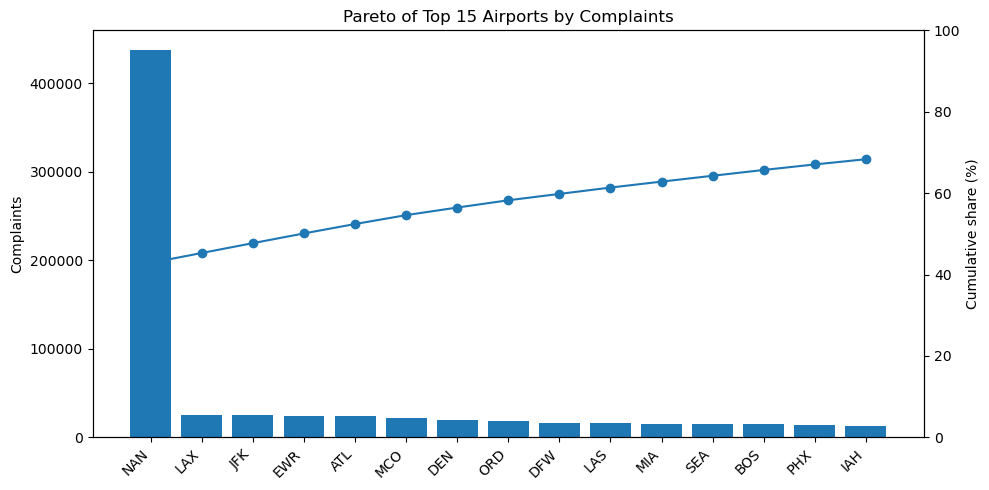

In [9]:
# Finds total complaints per airport and their cumulative share of complaints

d = dfs['by_airport'][['airport','count']].copy()
by_ap = (d.groupby('airport', dropna=False)['count']
           .sum()
           .sort_values(ascending=False)
           .reset_index(name='complaints'))

top = by_ap.head(15).copy()
total = by_ap['complaints'].sum()
top['cum_share_pct'] = top['complaints'].cumsum() / total * 100

fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(top))
ax.bar(x, top['complaints'])
ax.set_xticks(x); ax.set_xticklabels(top['airport'], rotation=45, ha='right')
ax.set_ylabel('Complaints'); ax.set_title('Pareto of Top 15 Airports by Complaints')

ax2 = ax.twinx()
ax2.plot(x, top['cum_share_pct'], marker='o')
ax2.set_ylabel('Cumulative share (%)'); ax2.set_ylim(0, 100)
plt.tight_layout(); plt.show()

## VISUAL 2 - Choropleth Map of Complaints

In [10]:
# Shows where complaints are geographically

ap = dfs['by_airport'].groupby('airport', dropna=False)['count'].sum().reset_index()

# Join IATA and state, only keeping U.S.
iata = dfs['iata_icao'][['iata','country_code','region_name']].copy()
iata['iata'] = iata['iata'].str.upper()
m = ap.merge(iata, left_on='airport', right_on='iata', how='inner')
m = m[m['country_code'].eq('US')]

# Change the States to USPS two-digit codes (covers 50 + DC)
state_to_code = {
 'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO',
 'Connecticut':'CT','Delaware':'DE','Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID',
 'Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA',
 'Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS',
 'Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH','New Jersey':'NJ',
 'New Mexico':'NM','New York':'NY','North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK',
 'Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD',
 'Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA',
 'West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','District of Columbia':'DC'}
m['state'] = m['region_name'].map(state_to_code)

# Aggregate to state and plot
st = m.dropna(subset=['state']).groupby('state')['count'].sum().reset_index()

fig = px.choropleth(
    st, locations='state', color='count',
    locationmode='USA-states', scope='usa',
    title='Choropleth of TSA Complaints by State')
fig.show()

## VISUAL 3 - Heat Map of Top 15 Seasonality

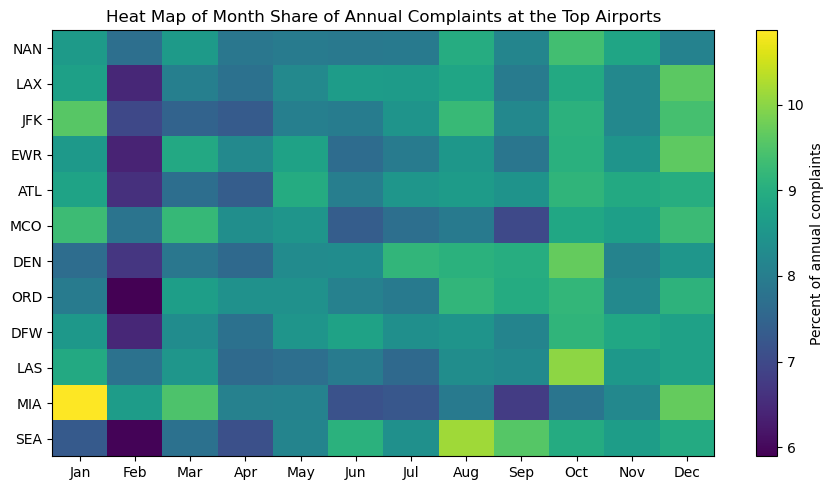

In [11]:
# Shows the monthly complaints at the Top 15 airports to see where seasonality happens by aggregating all years by month

d = dfs['by_airport'][['airport','year_month','count']].copy()
d['ym'] = pd.to_datetime(d['year_month'], errors='coerce'); d = d.dropna(subset=['airport','ym'])
d['mon'] = d['ym'].dt.month

top_air = (d.groupby('airport')['count'].sum().nlargest(12).index)
m = (d[d['airport'].isin(top_air)]
     .groupby(['airport','mon'])['count'].sum().unstack(fill_value=0)
     .reindex(index=top_air, columns=range(1,13)))
share = m.div(m.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9,5))
ax.grid(False)
im = ax.imshow(share.to_numpy(dtype=float), aspect='auto', cmap='viridis') 
ax.set_yticks(range(len(share.index))); ax.set_yticklabels(share.index)
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Heat Map of Month Share of Annual Complaints at the Top Airports')
plt.colorbar(im, ax=ax, label='Percent of annual complaints')  
plt.tight_layout(); plt.show()

## VISUAL 4 - Boxplot of Monthly Complaints at the Top 15

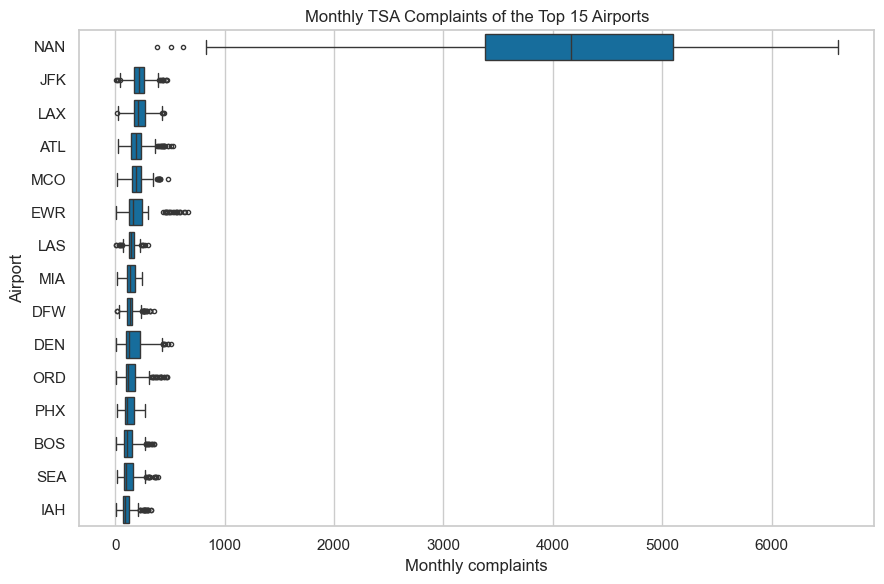

In [12]:
# Show Box Plot of Monthly TSA Complaints of the Top 15 Airports

top15_airports = top15['airport'].tolist()

d = dfs['by_airport'][['airport','year_month','count']].copy()
d['ym'] = pd.to_datetime(d['year_month'], errors='coerce')
d = d.dropna(subset=['airport','ym'])

m = (d.groupby(['airport', pd.Grouper(key='ym', freq='MS')])['count']
       .sum().reset_index())

m15 = m[m['airport'].isin(top15_airports)].copy()
order = (m15.groupby('airport')['count'].median()
         .sort_values(ascending=False).index.tolist())

sns.set_theme(style="whitegrid", palette="colorblind")
plt.figure(figsize=(9,6))
sns.boxplot(data=m15, y='airport', x='count', order=order, fliersize=3)
plt.title('Monthly TSA Complaints of the Top 15 Airports')
plt.xlabel('Monthly complaints'); plt.ylabel('Airport')
plt.tight_layout(); plt.show()

## VISUAL 5 - Bar Chart of Top Complaints at Top 15

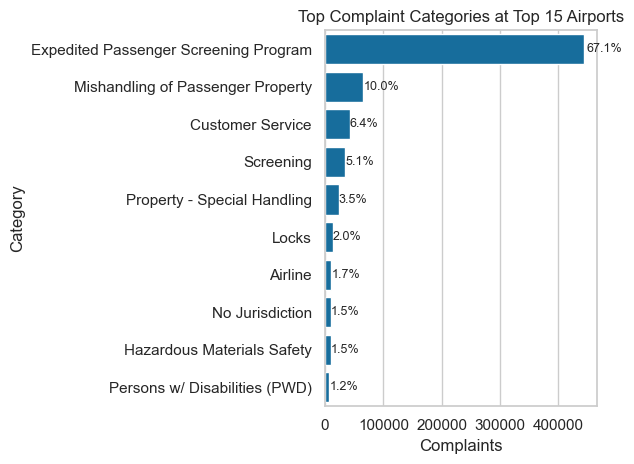

In [13]:
# Show the Top Complaint Categories at Top 15 Airports with percentages

C = dfs['by_category'][['airport','category','count']].copy()
C = C[C['airport'].isin(top15_airports)]

cat = (C.groupby('category')['count'].sum()
         .sort_values(ascending=False)
         .head(10)                                   
         .reset_index())
cat['share_pct'] = cat['count'] / cat['count'].sum() * 100

sns.set_theme(style="whitegrid", palette="colorblind")
ax = sns.barplot(data=cat, y='category', x='count')
ax.set_title('Top Complaint Categories at Top 15 Airports')
ax.set_xlabel('Complaints'); ax.set_ylabel('Category')

for i, r in cat.iterrows():
    ax.text(r['count']*1.01, i, f"{r['share_pct']:.1f}%", va='center', fontsize=9) 

plt.tight_layout(); plt.show()

In [14]:
# Computes Top 3 Categories, across Top 15 airports that account for percentage of complaints

C = dfs['by_category'][['airport','category','count']].dropna(subset=['airport','category']).copy()
if 'top15_airports' not in globals():
    top15_airports = (dfs['by_airport'].groupby('airport')['count'].sum()
                      .nlargest(15).index.tolist())

C = C[C['airport'].isin(top15_airports)]
C['count'] = pd.to_numeric(C['count'], errors='coerce').fillna(0)

tot = C['count'].sum()
top3 = (C.groupby('category')['count'].sum()
          .sort_values(ascending=False).head(3))

X = top3.sum() / tot * 100
cats = top3.index.tolist()
names = ', '.join(cats[:-1]) + ' and ' + cats[-1] if len(cats) > 1 else cats[0]

print(f"Across priority airports, {names} account for ~{X:.1f}% of complaints. Therefore recommend funding training or SOP fixes for those first.")

Across priority airports, Expedited Passenger Screening Program, Mishandling of Passenger Property and Customer Service account for ~79.2% of complaints. Therefore recommend funding training or SOP fixes for those first.


## VISUAL 6 - Line Chart of National Monthly Complaints over Time

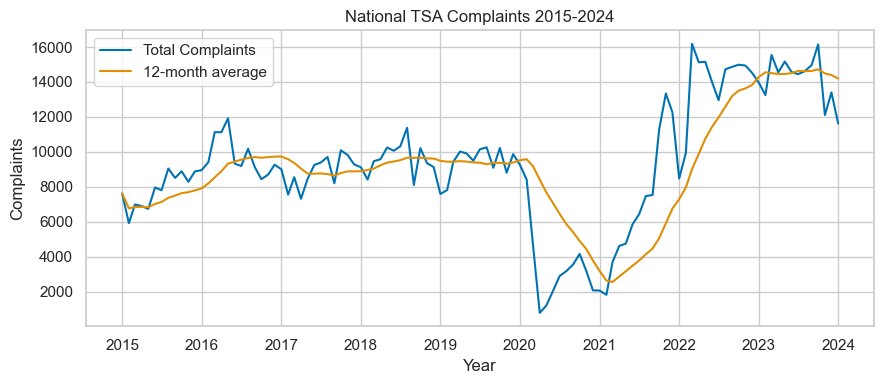

In [15]:
# Make visual of national annualized TSA complaints at all airports with a 12-month rolling average line for comparison

d = dfs['by_airport'][['year_month','count']].copy()
d['ym'] = pd.to_datetime(d['year_month'], errors='coerce')
m = d.groupby(pd.Grouper(key='ym', freq='MS'))['count'].sum().reset_index()
m['roll12'] = m['count'].rolling(12, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(m['ym'], m['count'], label='Total Complaints')
ax.plot(m['ym'], m['roll12'], label='12-month average')

ax.set_title('National TSA Complaints 2015-2024')
ax.set_xlabel('Year'); ax.set_ylabel('Complaints')
ax.legend(frameon=True)
plt.tight_layout(); plt.show()